# Project Setup

In [64]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [65]:
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

In [66]:
from sklearn.dummy import DummyClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

In [67]:
from sklearn.metrics import accuracy_score, recall_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Load the dataset

In [68]:
#Store the file path inside a variable named DATA_PATH
DATA_PATH = "/Users/will/Desktop/Year 3 - Semester 1/Artificial Intelligence and Machine Learning/CMP6202-coursework/data/raw/student_dropout.csv"

In [69]:
#Use pandas 'read_csv' function to read the data, store in variable named 'df'
#Important so original data isn't being modified, can reload this cell to restore dataset to original state
df = pd.read_csv(DATA_PATH)

In [70]:
df.head(20)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,8,5,2,1,1,1,13,10,6,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,6,1,11,1,1,1,1,3,4,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,5,1,1,1,22,27,10,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,8,2,15,1,1,1,23,27,6,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,12,1,3,0,1,1,22,28,10,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate
5,2,12,1,17,0,12,1,22,27,10,...,0,5,17,5,11.500000,5,16.2,0.3,-0.92,Graduate
6,1,1,1,12,1,1,1,13,28,8,...,0,8,8,8,14.345000,0,15.5,2.8,-4.06,Graduate
7,1,9,4,11,1,1,1,22,27,10,...,0,5,5,0,0.000000,0,15.5,2.8,-4.06,Dropout
8,1,1,3,10,1,1,15,1,1,10,...,0,6,7,6,14.142857,0,16.2,0.3,-0.92,Graduate
9,1,1,1,10,1,1,1,1,14,5,...,0,6,14,2,13.500000,0,8.9,1.4,3.51,Dropout


In [71]:
#Dataset has 4424 rows, 35 columns
print(df.shape)

(4424, 35)


# Checking dataset for any missing values

In [72]:
#Check for all missing values accross all columns, store in variable 'missing_values'
#Print the sum of all the missing values
missing_values = df.isnull().sum()
print(missing_values.sum())

0


In [73]:
#Check for any missing values (returns True or False)
print(df.isnull().values.any())

False


# Dropping any rows with missing values

 My dataset doesn't contain any rows with missing values, but below is the code that I would use if I were to drop rows. I also understand that dropping rows with missing values isn't always the best approach, methods such as IMPUTATION should be considered

In [74]:
df = df.dropna()

In [75]:
#Same amount of rows and columns as previously (before dropping missing values)
print(df.shape)

(4424, 35)


# Checking for columns that store text

In [76]:
#Checking all of the columns within my dataset to see what 'types' they are
print(df.dtypes)

Marital status                                      int64
Application mode                                    int64
Application order                                   int64
Course                                              int64
Daytime/evening attendance                          int64
Previous qualification                              int64
Nacionality                                         int64
Mother's qualification                              int64
Father's qualification                              int64
Mother's occupation                                 int64
Father's occupation                                 int64
Displaced                                           int64
Educational special needs                           int64
Debtor                                              int64
Tuition fees up to date                             int64
Gender                                              int64
Scholarship holder                                  int64
Age at enrollm

In [77]:
#Beacause my dataset is 'multiclass classification', I want to keep the targer value as a String (enrolled, dropout, grduate)
print(df.select_dtypes(include=['object', 'string']).columns)

Index(['Target'], dtype='str')


If I wanted to convert any columns or my target value into a numerical value I would use 'LabelEncoder'. Please see the commented code below. 

In [78]:
# Converting specific columns into numerical values

# encoder = LabelEncoder()
# df['columnname'] = encoder.fit_transform(encoder['columnname'])

In [79]:
# Converting targer value into numerical values
# df['Target'] = encoder.fit_transform(encoder['Target])

# Seperating the dataset between X and Y (X = prediction columns, Y = target column)

In [80]:
#X = dataset with target column dropped/removed
X = df.drop(columns=['Target'])

#Y = target column
y = df['Target']


# Create the training and test splits

In [81]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training students: ", len(X_train))
print("Test students: ", len(X_test))

Training students:  3539
Test students:  885


In [82]:
X_train.head(2)

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Nacionality,Mother's qualification,Father's qualification,Mother's occupation,...,Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP
2283,1,14,1,10,1,14,1,2,1,2,...,0,6,10,13,10,11.8,0,13.9,-0.3,0.79
3874,1,12,1,8,1,1,1,1,1,12,...,1,0,5,5,0,0.0,5,12.7,3.7,-1.70


In [83]:
y_train.head(2)

2283    Graduate
3874     Dropout
Name: Target, dtype: str

# Baseline for each model to beat

In [84]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

baseline = DummyClassifier(strategy="most_frequent", random_state=42)
baseline_scores = cross_val_score(baseline, X_train, y_train, cv=skf)

baseline_scores

array([0.5       , 0.5       , 0.49858757, 0.49858757, 0.49929279])

In [85]:
baseline_average = baseline_scores.mean().round(2)
print(baseline_average)

0.5


# Naive Bays 


In [94]:
gnb = GaussianNB()
gnb_scores = cross_val_score(gnb, X_train, y_train, cv=skf)

gnb_scores


array([0.68926554, 0.70338983, 0.69491525, 0.65819209, 0.67751061])

In [95]:
gnb_average = gnb_scores.mean().round(2)
print(gnb_average)

0.68


# Decision Tree

In [86]:
dt = DecisionTreeClassifier(random_state=42)
dt_scores = cross_val_score(dt, X_train, y_train, cv=skf, scoring="accuracy")

dt_scores

array([0.67372881, 0.6779661 , 0.67514124, 0.68220339, 0.66760962])

In [87]:
dt_average = dt_scores.mean().round(2)
dt_average

np.float64(0.68)

# Random Forest

In [106]:
rf = RandomForestClassifier(random_state=42)
rf_scores = cross_val_score(rf, X_train, y_train, cv=skf, scoring="accuracy")

rf_scores

array([0.78531073, 0.75564972, 0.78954802, 0.75847458, 0.77227723])

In [89]:
rf_average = rf_scores.mean().round(2)
rf_average

np.float64(0.77)

# Model Comparison (before tuning)

In [96]:
my_models = pd.DataFrame({
    'Models': ['Baseline', 'Naive Bays', 'Decision Tree', 'Random Forest'],
    'Accuracy': [baseline_average, gnb_average, dt_average, rf_average]
})

In [98]:
my_models.sort_values(by='Accuracy', ascending=True)

,Models,Accuracy
0,Baseline,0.50
1,Naive Bays,0.68
2,Decision Tree,0.68
3,Random Forest,0.77


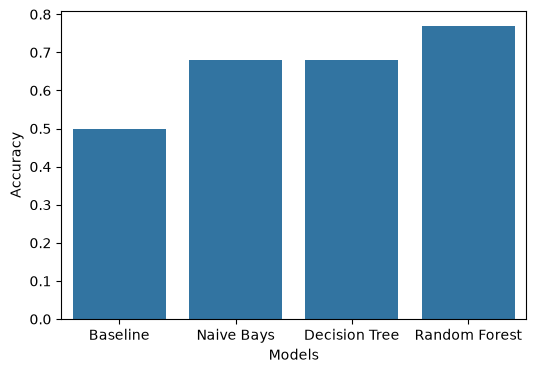

In [99]:
plt.figure(figsize=(6,4))
sns.barplot(data = my_models, x = 'Models', y = 'Accuracy')

plt.show()


# Fine Tune the Best Model (Random Forest)

In [102]:
print("Baseline     :", round(baseline_scores.mean(), 3))
print("Naive Bayes  :", round(gnb_scores.mean(), 3))
print("Decision Tree:", round(dt_scores.mean(), 3))
print("Random Forest:", round(rf_scores.mean(), 3))

Baseline     : 0.499
Naive Bayes  : 0.685
Decision Tree: 0.675
Random Forest: 0.772


# Hyperparameter Tuning

In [103]:
param_grid = {
    "n_estimators" : [10, 50, 100, 200, 300],
    "max_depth": [2, 3, 5, 7, 10],
}

grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=skf,
    scoring="accuracy"
)
grid_rf.fit(X_train, y_train)

print("Best settings: ", grid_rf.best_params_)
print("Best average accuracy: ", round(grid_rf.best_score_, 3))

Best settings:  {'max_depth': 10, 'n_estimators': 100}
Best average accuracy:  0.769


# Testing all models on the test set

In [ ]:
# The baseline model
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)

# 